In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd

# --- Project folders ---
# Notebooks run from the notebooks/ folder, so go up one level if needed
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
REPORT_DIR = PROJECT_ROOT / "docs"
RESULTS_DIR = PROJECT_ROOT / "results" / "step3"
MODEL_DIR = PROJECT_ROOT / "models"

for folder in (PROCESSED_DIR, RESULTS_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# --- Input files ---
COURSES_FILE = RAW_DIR / "courses.csv"
ROOMS_FILE = RAW_DIR / "rooms.csv"

# --- Column names used by the model ---
COURSE_FEATURES = [
    "course_id", "cohort_id", "faculty_id",
    "weekly_sessions", "duration_slots",
    "required_room_type", "students",
]
ROOM_FEATURES = ["room_id", "capacity", "room_type"]

# --- Reproducibility ---
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("courses.csv found:", COURSES_FILE.exists())
print("rooms.csv found:", ROOMS_FILE.exists())

PROJECT_ROOT: /Users/varunbhargava/Desktop/SC05-University-Timetable-Optimization-Engine/SC05-University-Timetable-Optimization-Engine
courses.csv found: True
rooms.csv found: True


In [2]:
%pip install matplotlib


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install scikit-learn


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
def load_clean_csv(filename, required_columns=None, folder=PROCESSED_DIR):
    """Load a CSV from the processed data folder and check that it is usable."""
    path = Path(folder) / filename

    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

    df = pd.read_csv(path)

    if df.empty:
        raise ValueError(f"{filename} has no rows")

    if required_columns is not None:
        missing_cols = [c for c in required_columns if c not in df.columns]
        if missing_cols:
            raise ValueError(f"{filename} is missing columns: {missing_cols}")

    missing_values = int(df.isna().sum().sum())
    if missing_values > 0:
        raise ValueError(f"{filename} has {missing_values} missing values")

    print(f"{filename}: {df.shape[0]} rows, {df.shape[1]} columns, no missing values")
    return df

In [5]:
processed_files = sorted(PROCESSED_DIR.glob("*.csv"))
print("Files in data/processed:", [f.name for f in processed_files])

for f in processed_files:
    df = load_clean_csv(f.name)
    display(df.head())

Files in data/processed: []


In [6]:
for f in sorted(DATA_DIR.rglob("*")):
    if f.is_file() and f.name != ".DS_Store":
        print(f.relative_to(PROJECT_ROOT))

data/01_data_inspection.ipynb
data/README.md
data/courses.csv
data/invalid_data/invalid_courses.csv
data/raw/.gitkeep
data/raw/courses.csv
data/raw/rooms.csv
data/raw/timeslots.csv
data/rooms.csv
data/test_cases.md
data/timeslots.csv


In [7]:
courses = load_clean_csv("courses.csv", COURSE_FEATURES, folder=RAW_DIR)
rooms = load_clean_csv("rooms.csv", ROOM_FEATURES, folder=RAW_DIR)
timeslots = load_clean_csv("timeslots.csv", folder=RAW_DIR)

for name, df in [("courses", courses), ("rooms", rooms), ("timeslots", timeslots)]:
    print(f"\n{name}: columns = {list(df.columns)}")
    display(df.head())

print("\nRoom types needed by courses:")
print(courses["required_room_type"].value_counts())
print("\nRoom types available:")
print(rooms["room_type"].value_counts())

courses.csv: 5 rows, 7 columns, no missing values
rooms.csv: 3 rows, 3 columns, no missing values
timeslots.csv: 10 rows, 4 columns, no missing values

courses: columns = ['course_id', 'cohort_id', 'faculty_id', 'weekly_sessions', 'duration_slots', 'required_room_type', 'students']


,course_id,cohort_id,faculty_id,weekly_sessions,duration_slots,required_room_type,students
0,C01,G1,F1,2,1,classroom,35
1,C02,G1,F2,2,1,lab,30
2,C03,G2,F1,1,2,classroom,40
3,C04,G2,F3,2,1,classroom,45
4,C05,G1,F3,1,1,lab,25



rooms: columns = ['room_id', 'capacity', 'room_type']


,room_id,capacity,room_type
0,R01,60,classroom
1,R02,40,classroom
2,R03,35,lab



timeslots: columns = ['slot_id', 'day', 'time', 'preferred']


,slot_id,day,time,preferred
0,S01,Monday,09:00,yes
1,S02,Monday,11:00,yes
2,S03,Monday,14:00,no
3,S04,Tuesday,09:00,yes
4,S05,Tuesday,11:00,yes



Room types needed by courses:
required_room_type
classroom    3
lab          2
Name: count, dtype: int64

Room types available:
room_type
classroom    2
lab          1
Name: count, dtype: int64


In [8]:
# INPUTS: one row per weekly session that must be scheduled
sessions = courses.loc[courses.index.repeat(courses["weekly_sessions"])].reset_index(drop=True)
sessions["session_no"] = sessions.groupby("course_id").cumcount() + 1
sessions["session_id"] = sessions["course_id"] + "_S" + sessions["session_no"].astype(str)

print("Sessions to schedule:", len(sessions))
print("Rooms available:", len(rooms))
print("Timeslots available:", len(timeslots))
print("Placement options per session:", len(rooms) * len(timeslots))

# OUTPUT (produced later by the GA): one (room, timeslot) choice per session
display(sessions[["session_id", "course_id", "cohort_id", "faculty_id", "required_room_type", "students"]])

Sessions to schedule: 8
Rooms available: 3
Timeslots available: 10
Placement options per session: 30


,session_id,course_id,cohort_id,faculty_id,required_room_type,students
0,C01_S1,C01,G1,F1,classroom,35
1,C01_S2,C01,G1,F1,classroom,35
2,C02_S1,C02,G1,F2,lab,30
3,C02_S2,C02,G1,F2,lab,30
4,C03_S1,C03,G2,F1,classroom,40
5,C04_S1,C04,G2,F3,classroom,45
6,C04_S2,C04,G2,F3,classroom,45
7,C05_S1,C05,G1,F3,lab,25


In [9]:
# --- GA configuration (reproducible) ---
GA_CONFIG = {
    "population_size": 50,
    "generations": 100,
    "crossover_rate": 0.8,
    "mutation_rate": 0.05,
    "tournament_size": 3,
    "elitism": 2,
    "random_seed": RANDOM_SEED,
}

# --- Chromosome design: one (room, timeslot) gene per session ---
N_SESSIONS = len(sessions)
N_ROOMS = len(rooms)
N_SLOTS = len(timeslots)

def random_individual(rng):
    return [(int(rng.integers(N_ROOMS)), int(rng.integers(N_SLOTS)))
            for _ in range(N_SESSIONS)]

# --- Fitness penalties (lower total = better timetable) ---
PENALTY_WEIGHTS = {
    "room_clash": 1000,
    "faculty_clash": 1000,
    "cohort_clash": 1000,
    "capacity": 500,
    "room_type": 500,
}

rng = np.random.default_rng(GA_CONFIG["random_seed"])
print("Genes per timetable:", N_SESSIONS)
print("Search space size:", f"{(N_ROOMS * N_SLOTS) ** N_SESSIONS:,}")
print("Example random timetable:", random_individual(rng))

Genes per timetable: 8
Search space size: 656,100,000,000
Example random timetable: [(0, 7), (1, 4), (1, 8), (0, 6), (0, 0), (1, 9), (2, 7), (2, 7)]


In [10]:
print("GA_CONFIG:")
for k, v in GA_CONFIG.items():
    print(f"  {k}: {v}")

print("\nPENALTY_WEIGHTS:")
for k, v in PENALTY_WEIGHTS.items():
    print(f"  {k}: {v}")

GA_CONFIG:
  population_size: 50
  generations: 100
  crossover_rate: 0.8
  mutation_rate: 0.05
  tournament_size: 3
  elitism: 2
  random_seed: 42

PENALTY_WEIGHTS:
  room_clash: 1000
  faculty_clash: 1000
  cohort_clash: 1000
  capacity: 500
  room_type: 500


In [11]:
room_cap = rooms["capacity"].to_numpy()
room_type = rooms["room_type"].to_numpy()
s_fac = sessions["faculty_id"].to_numpy()
s_coh = sessions["cohort_id"].to_numpy()
s_students = sessions["students"].to_numpy()
s_type = sessions["required_room_type"].to_numpy()

def fitness(ind):
    pen = 0
    for i in range(N_SESSIONS):
        r, t = ind[i]
        if room_cap[r] < s_students[i]:
            pen += PENALTY_WEIGHTS["capacity"]
        if room_type[r] != s_type[i]:
            pen += PENALTY_WEIGHTS["room_type"]
        for j in range(i + 1, N_SESSIONS):
            r2, t2 = ind[j]
            if t == t2:
                if r == r2:
                    pen += PENALTY_WEIGHTS["room_clash"]
                if s_fac[i] == s_fac[j]:
                    pen += PENALTY_WEIGHTS["faculty_clash"]
                if s_coh[i] == s_coh[j]:
                    pen += PENALTY_WEIGHTS["cohort_clash"]
    return pen

In [12]:
def tournament(pop, scores, rng):
    idx = rng.choice(len(pop), GA_CONFIG["tournament_size"], replace=False)
    return pop[min(idx, key=lambda k: scores[k])]

def crossover(a, b, rng):
    if rng.random() < GA_CONFIG["crossover_rate"]:
        cut = int(rng.integers(1, N_SESSIONS))
        return a[:cut] + b[cut:]
    return list(a)

def mutate(ind, rng):
    return [(int(rng.integers(N_ROOMS)), int(rng.integers(N_SLOTS)))
            if rng.random() < GA_CONFIG["mutation_rate"] else g for g in ind]

In [13]:

rng = np.random.default_rng(GA_CONFIG["random_seed"])
population = [random_individual(rng) for _ in range(GA_CONFIG["population_size"])]
best_history = []

for gen in range(GA_CONFIG["generations"]):
    scores = [fitness(ind) for ind in population]
    order = np.argsort(scores)
    best_history.append(scores[order[0]])
    new_pop = [population[k] for k in order[:GA_CONFIG["elitism"]]]
    while len(new_pop) < GA_CONFIG["population_size"]:
        p1 = tournament(population, scores, rng)
        p2 = tournament(population, scores, rng)
        new_pop.append(mutate(crossover(p1, p2, rng), rng))
    population = new_pop

scores = [fitness(ind) for ind in population]
best_idx = int(np.argmin(scores))
best_timetable = population[best_idx]

print("Generations completed:", GA_CONFIG["generations"])
print("Starting best penalty:", best_history[0])
print("Final best penalty (like final loss):", scores[best_idx])

Generations completed: 100
Starting best penalty: 2000
Final best penalty (like final loss): 0


In [14]:
def evaluate_timetable(ind):
    """Return a metrics row for one timetable."""
    room_clashes = faculty_clashes = cohort_clashes = 0
    capacity_viol = type_viol = 0
    for i in range(N_SESSIONS):
        r, t = ind[i]
        capacity_viol += int(room_cap[r] < s_students[i])
        type_viol += int(room_type[r] != s_type[i])
        for j in range(i + 1, N_SESSIONS):
            r2, t2 = ind[j]
            if t == t2:
                room_clashes += int(r == r2)
                faculty_clashes += int(s_fac[i] == s_fac[j])
                cohort_clashes += int(s_coh[i] == s_coh[j])
    hard = room_clashes + faculty_clashes + cohort_clashes + capacity_viol + type_viol
    return {
        "total_penalty": fitness(ind),
        "room_clashes": room_clashes,
        "faculty_clashes": faculty_clashes,
        "cohort_clashes": cohort_clashes,
        "capacity_violations": capacity_viol,
        "room_type_violations": type_viol,
        "feasible": hard == 0,
    }

# Random baseline: best of 5000 random timetables (same seed)
base_rng = np.random.default_rng(RANDOM_SEED)
random_runs = [random_individual(base_rng) for _ in range(5000)]
best_random = min(random_runs, key=fitness)
avg_random_penalty = float(np.mean([fitness(x) for x in random_runs]))

metrics = pd.DataFrame(
    [evaluate_timetable(best_random), evaluate_timetable(best_timetable)],
    index=["Random baseline (best of 5000)", "Genetic Algorithm"],
)
display(metrics)
print("Average penalty of a random timetable:", round(avg_random_penalty, 1))

,total_penalty,room_clashes,faculty_clashes,cohort_clashes,capacity_violations,room_type_violations,feasible
Random baseline (best of 5000),500,0,0,0,0,1,False
Genetic Algorithm,0,0,0,0,0,0,True


Average penalty of a random timetable: 5606.0


In [15]:
print(metrics.T.to_string())

                     Random baseline (best of 5000) Genetic Algorithm
total_penalty                                   500                 0
room_clashes                                      0                 0
faculty_clashes                                   0                 0
cohort_clashes                                    0                 0
capacity_violations                               0                 0
room_type_violations                              1                 0
feasible                                      False              True


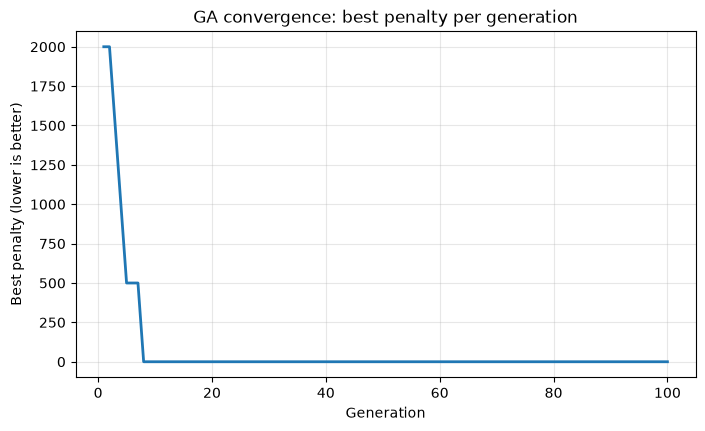

Saved: /Users/varunbhargava/Desktop/SC05-University-Timetable-Optimization-Engine/SC05-University-Timetable-Optimization-Engine/results/step3/step3_ga_convergence_curve.png


In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(best_history) + 1), best_history, linewidth=2)
ax.set_xlabel("Generation")
ax.set_ylabel("Best penalty (lower is better)")
ax.set_title("GA convergence: best penalty per generation")
ax.grid(True, alpha=0.3)

out_path = RESULTS_DIR / "step3_ga_convergence_curve.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

In [17]:
def show_room_type_matrix(timetable, title, save_name=None):
    """Rows = room type the session needs (actual), columns = room type it was placed in (assigned)."""
    needed = [s_type[i] for i in range(N_SESSIONS)]
    placed = [room_type[timetable[i][0]] for i in range(N_SESSIONS)]
    labels = sorted(set(room_type) | set(s_type))

    matrix = pd.crosstab(
        pd.Categorical(needed, categories=labels),
        pd.Categorical(placed, categories=labels),
        rownames=["Needed (actual)"],
        colnames=["Placed in (assigned)"],
        dropna=False,
    )
    print(title)
    display(matrix)

    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.imshow(matrix.values, cmap="Blues")
    ax.set_xticks(range(len(labels)), labels)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("Placed in (assigned)")
    ax.set_ylabel("Needed (actual)")
    ax.set_title(title)
    for r in range(len(labels)):
        for c in range(len(labels)):
            ax.text(c, r, int(matrix.values[r, c]), ha="center", va="center")
    if save_name:
        fig.savefig(RESULTS_DIR / save_name, dpi=150, bbox_inches="tight")
    plt.show()
    return matrix

In [18]:
def run_ga(seed):
    r = np.random.default_rng(seed)
    pop = [random_individual(r) for _ in range(GA_CONFIG["population_size"])]
    for _ in range(GA_CONFIG["generations"]):
        sc = [fitness(i) for i in pop]
        order = np.argsort(sc)
        nxt = [pop[k] for k in order[:GA_CONFIG["elitism"]]]
        while len(nxt) < GA_CONFIG["population_size"]:
            p1 = tournament(pop, sc, r)
            p2 = tournament(pop, sc, r)
            nxt.append(mutate(crossover(p1, p2, r), r))
        pop = nxt
    sc = [fitness(i) for i in pop]
    best = pop[int(np.argmin(sc))]
    return best, min(sc)

rows = []
for seed in [1, 7, 21, 99, 123, 2024, 31415, 777, 555, 10]:
    best, pen = run_ga(seed)
    row = evaluate_timetable(best)
    row["seed"] = seed
    rows.append(row)

final_check = pd.DataFrame(rows).set_index("seed")
display(final_check)
print("Seeds that found a feasible timetable:",
      int(final_check["feasible"].sum()), "of", len(final_check))
print("Average final penalty:", final_check["total_penalty"].mean())

,total_penalty,room_clashes,faculty_clashes,cohort_clashes,capacity_violations,room_type_violations,feasible
seed,,,,,,,
1,0,0,0,0,0,0,True
7,0,0,0,0,0,0,True
21,0,0,0,0,0,0,True
99,0,0,0,0,0,0,True
123,0,0,0,0,0,0,True
2024,0,0,0,0,0,0,True
31415,0,0,0,0,0,0,True
777,0,0,0,0,0,0,True
555,0,0,0,0,0,0,True


Seeds that found a feasible timetable: 10 of 10
Average final penalty: 0.0


Random baseline: room type needed vs placed


Placed in (assigned),classroom,lab
Needed (actual),,
classroom,5,0
lab,1,2


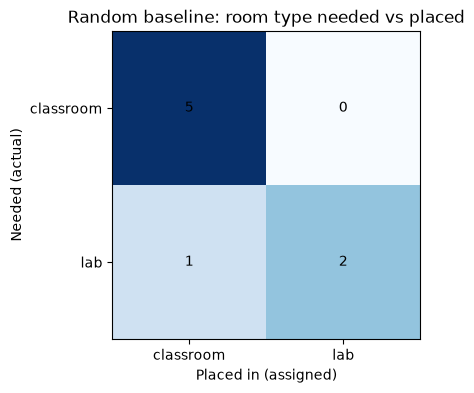

Genetic Algorithm: room type needed vs placed


Placed in (assigned),classroom,lab
Needed (actual),,
classroom,5,0
lab,0,3


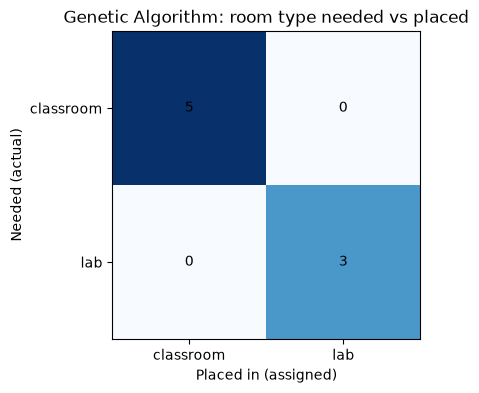

In [19]:
m_random = show_room_type_matrix(
    best_random,
    "Random baseline: room type needed vs placed",
    save_name="step3_room_type_matrix_random.png",
)

m_ga = show_room_type_matrix(
    best_timetable,
    "Genetic Algorithm: room type needed vs placed",
    save_name="step3_room_type_matrix_ga.png",
)

In [20]:
import json
from datetime import datetime

metrics.to_csv(RESULTS_DIR / "step3_metrics.csv")
final_check.to_csv(RESULTS_DIR / "step3_final_check_seeds.csv")

best_table = sessions[["session_id", "course_id", "cohort_id", "faculty_id", "required_room_type", "students"]].copy()
best_table["room_id"] = [rooms.iloc[best_timetable[i][0]]["room_id"] for i in range(N_SESSIONS)]
best_table["timeslot"] = [int(best_timetable[i][1]) for i in range(N_SESSIONS)]
best_table.to_csv(RESULTS_DIR / "step3_best_timetable.csv", index=False)

history = pd.DataFrame({"generation": range(1, len(best_history) + 1), "best_penalty": best_history})
history.to_csv(RESULTS_DIR / "step3_convergence_history.csv", index=False)
print("CSV files saved")

CSV files saved


In [21]:
import json
meta = {
    "step": 3,
    "method": "Genetic Algorithm timetable",
    "generations": len(best_history),
    "final_best_fitness": float(best_history[-1]),
}
with open(RESULTS_DIR / "step3_metadata.json", "w") as f:
    json.dump(meta, f, indent=2)
print("Saved Step 3 evidence files.")

Saved Step 3 evidence files.
